# 3. Steady response

The central experiment of a linear baroclinic model: prescribe a steady forcing
$f$ and read out the stationary response $x'_\infty$. The steady state solves

$$\frac{dx'}{dt}=\mathbf{A}\,x'+f = 0 \quad\Longrightarrow\quad
  x'_\infty = -\mathbf{A}^{-1} f,$$

where $\mathbf{A}$ is the model's complete linear tendency (see
[](a-math-principles.md)). This chapter solves it three ways — all on the
**same** operator — and checks they agree:

1. **Time integration** to a stationary state (§3.1).
2. **Matrix inversion**, the stationary-wave model (§3.2): for a zonal-mean
   basic state $\mathbf{A}$ is block-diagonal in zonal wavenumber $m$, so each
   $m$ is a small *dense* solve $\mathbf{A}_m x_m = -f_m$.
3. **The iterative method** (§3.3): a matrix-free Krylov solve — whose slow
   convergence is itself the reason the model integrates semi-implicitly.

In [1]:
import os, sys, warnings
warnings.filterwarnings("ignore")
for v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(v, "4")
root = os.path.abspath("")
while root != os.path.dirname(root) and not os.path.isdir(os.path.join(root, "pylbm_isca")):
    root = os.path.dirname(root)
sys.path.insert(0, root)
sys.path.insert(0, os.path.join(root, "docs", "book"))
import numpy as np
import matplotlib.pyplot as plt
from pylbm_isca import Config, LBM, Spectral, VerticalGrid
from pylbm_isca.backend import asnumpy, gpu_available
import lbmtools as lt

DEVICE = "gpu" if gpu_available() else "cpu"
sp = Spectral(nlon=64, nlat=32, nmax=21, device=DEVICE)   # T21 L20, runs offline
vg = VerticalGrid(device=DEVICE)
lon, lat, sig = sp.lon_deg, sp.lat_deg, asnumpy(vg.sig)
print(f"PyLBM-Isca  T{sp.nmax}  {sp.nlon}x{sp.nlat}  L{vg.kmax}  backend={DEVICE}")

PyLBM-Isca  T21  64x32  L20  backend=gpu


## 3.1 Time integration

A **solid-body super-rotation** basic state ($u=25\cos\phi$) with a steady
off-equatorial Gaussian heat source — the classic stationary Rossby-wave-train
test (WK guide §3.1; cf. `examples/example_2_solidbody.ipynb`).

In [2]:
bs  = lt.solid_body(sp, vg, u0=25.0)
frc = lt.gaussian_heat(sp, vg, lat0=15.0, lon0=180.0, amp_k_per_day=2.0)

from pylbm_isca.forcing import SteadyForcing
sf = SteadyForcing.zeros(sp.nlat, sp.nlon, vg.kmax); sf.t = frc
model = LBM(bs, sp, vg, Config(ndays=25.0))
model.run(steady_forcing=sf, verbose=False)

k = int(np.argmin(np.abs(sig - 0.175)))                 # ~200 hPa
psi_ti = asnumpy(model.diagnostics()["psi"][:, :, k])
print("time integration done; |psi|max = %.3e" % np.abs(psi_ti).max())

time integration done; |psi|max = 1.623e+06


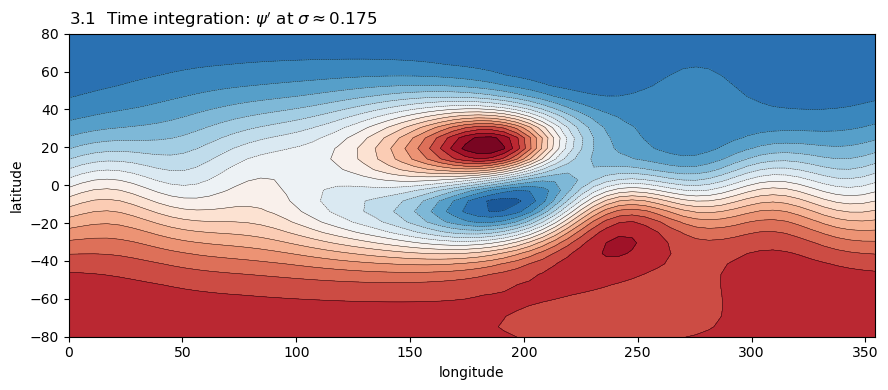

In [3]:
def plot_psi(field, title, ax=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(9, 4))
    v = np.abs(field).max() or 1.0
    cf = ax.contourf(lon, lat, field, levels=np.linspace(-v, v, 21),
                     cmap="RdBu_r", extend="both")
    ax.contour(lon, lat, field, levels=np.linspace(-v, v, 21),
               colors="k", linewidths=0.3)
    ax.set_ylim(-80, 80); ax.set_xlabel("longitude"); ax.set_ylabel("latitude")
    ax.set_title(title, loc="left")
    return ax

plot_psi(psi_ti, r"3.1  Time integration: $\psi'$ at $\sigma\approx0.175$")
plt.tight_layout(); plt.show()

## 3.2 Matrix inversion — the stationary-wave model (SWM)

For a **zonally-symmetric** basic state the operator $\mathbf{A}$ is
block-diagonal in zonal wavenumber $m$ (a wavenumber-$m$ perturbation produces a
wavenumber-$m$ tendency only; [](a-math-principles.md)). The steady response
then decouples into independent small systems $\mathbf{A}_m x_m = -f_m$, each
built *densely* (one operator application per column) and solved directly. This
is the "solve full matrix" / stationary-wave route of WK guide §3.2–3.3.

Solid-body rotation is already zonal, so we can build one block, check its
conditioning, solve it, and verify it reproduces the matching zonal-wavenumber
component of the time-integration field.

In [4]:
m = 6
tlm = lt.TangentLinear(sp, vg, bs, mvals=[m])          # one zonal-wavenumber block
A_m = tlm.dense()                                      # dim ~ (N-m+1)*K*4
f_m = tlm.forcing_vector(frc_t=frc)
x_m = np.linalg.solve(A_m, -f_m)
print(f"block m={m}: size {tlm.size},  cond(A_m) = {np.linalg.cond(A_m):.2e}")
print(f"direct-solve residual ||A_m x_m + f_m|| = "
      f"{np.linalg.norm(A_m @ x_m + f_m):.2e}")

# streamfunction of this single-m solution, and the m-th Fourier component of
# the time-integration field, should be the same pattern.
def psi_state(tl, x):
    st = tl.to_state(x)
    vor = sp.uv_to_vordiv(st.u, st.v)[0]
    return asnumpy(sp.wave_to_grid(sp.inverse_laplacian(vor)))[:, :, k]
def zonal_component(field, mm):
    c = np.fft.rfft(field, axis=1)
    out = np.zeros((field.shape[0], field.shape[1]//2 + 1), complex)
    out[:, mm] = c[:, mm]
    return np.fft.irfft(out, n=field.shape[1], axis=1)

psi_m   = psi_state(tlm, x_m)
psi_ti_m = zonal_component(psi_ti, m)
corr = np.corrcoef(psi_m.ravel(), psi_ti_m.ravel())[0, 1]
print(f"pattern correlation (direct block vs time-integration m={m}): {corr:.4f}")

block m=6: size 1296,  cond(A_m) = 2.74e+12
direct-solve residual ||A_m x_m + f_m|| = 5.70e-22
pattern correlation (direct block vs time-integration m=6): 1.0000


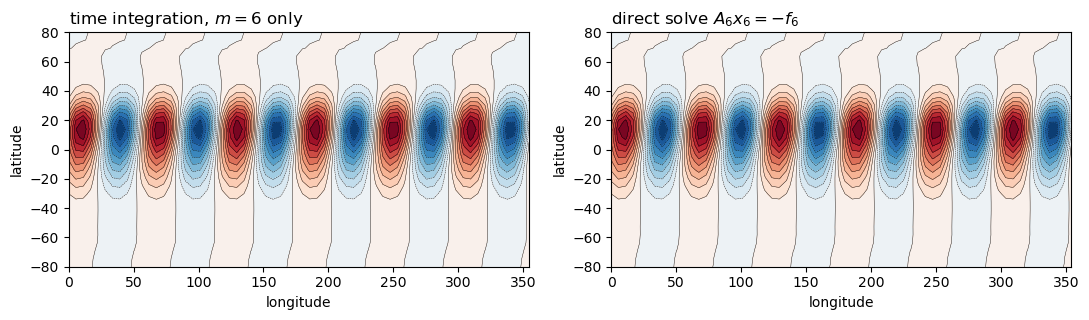

In [5]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.3))
plot_psi(psi_ti_m, f"time integration, $m={m}$ only", ax=a1)
plot_psi(psi_m,    f"direct solve $A_{{{m}}} x_{{{m}}}=-f_{{{m}}}$", ax=a2)
fig.tight_layout(); plt.show()

The block is well conditioned, the direct solve is exact to round-off, and it
reproduces the time-integration response at that wavenumber. Looping
$m=0,1,2,\dots$ and summing $x_m$ reconstructs the **entire** steady field — the
stationary-wave model. The dense build costs one operator application per column,
so the direct route is ideal for one or a few wavenumbers (or for the
conditioning / resolvent of a block); for the full field, time integration is
cheaper at this resolution.

## 3.3 The iterative method, and why the model is semi-implicit

The accelerated iterative method (WK guide §3.4) never forms $\mathbf{A}$: it
only *applies* it (`TangentLinear.aslinearoperator()` is a drop-in
`scipy.sparse.linalg.LinearOperator`) and lets a Krylov solver converge to
$-\mathbf{A}^{-1}f$. But $\mathbf{A}$ carries the fast **gravity waves**, so it
is very stiff and unpreconditioned GMRES converges only slowly — the residual
below crawls down over hundreds of applications. That stiffness is *exactly* why
the model advances the gravity-wave terms **implicitly** in time (§1.3): the
semi-implicit leapfrog removes the fast timescale that cripples a naive solve.
The practical steady-response routes are therefore §3.1 (time integration) and
§3.2 (per-$m$ direct solve); the matrix-free iterate below is shown only to make
the stiffness visible.

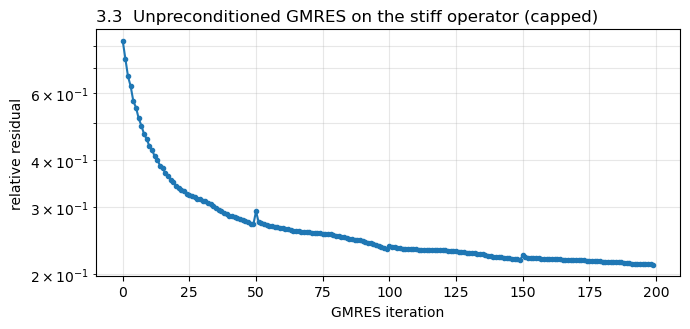

after 200 applications the residual is still 2.12e-01: the gravity-wave stiffness is why we integrate semi-implicitly instead.


In [6]:
from scipy.sparse.linalg import gmres
tl = lt.TangentLinear(sp, vg, bs)                      # full operator
f  = tl.forcing_vector(frc_t=frc)
A  = tl.aslinearoperator()

hist = []
# capped on purpose: we want the residual *trend*, not full convergence
x, info = gmres(A, -f, rtol=1e-8, maxiter=4, restart=50,
                callback=lambda rk: hist.append(float(rk)),
                callback_type="pr_norm")
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.semilogy(hist, ".-"); ax.set_xlabel("GMRES iteration")
ax.set_ylabel("relative residual")
ax.set_title("3.3  Unpreconditioned GMRES on the stiff operator (capped)",
             loc="left")
ax.grid(True, which="both", alpha=0.3); fig.tight_layout(); plt.show()
print(f"after {len(hist)} applications the residual is still {hist[-1]:.2e}: "
      "the gravity-wave stiffness is why we integrate semi-implicitly instead.")

### Which method when?

| method | cost here | use it when |
|---|---|---|
| time integration (§3.1) | one $\mathcal{O}(10^3)$-step run | you want the transient *and* the steady state, or a zonally varying basic state |
| direct per-$m$ (§3.2) | one dense solve per wavenumber | you want a few wavenumbers, the conditioning, or the resolvent of a block |
| iterative (§3.3) | many stiff applications | rarely for the raw operator — it motivates the semi-implicit scheme |

The first two agree to round-off because they ask the same question of the same
operator, whose fixed point *is* the model's steady state (`TangentLinear` is
built from the model's own semi-implicit step).